# Support Vector Machine (SVM From Scratch)

Eksperimen implementasi `SVM` *from scratch* dengan solver *Sequential Minimal Optimization* (SMO) orde kedua dan dukungan kernel *Linear*, *Polynomial*, serta *Gaussian* (RBF). Notebook ini mencakup:
1. Perbandingan kuantitatif ketiga kernel terhadap `sklearn.svm.SVC` pada subset terstratifikasi 5.000 baris.
2. Evaluasi SVM RBF pada fitur hasil rekayasa (89 fitur).
3. Visualisasi bidang pemisah ($f(x)=0$), *margin* ($f(x)=\pm 1$), dan *support vector* pada proyeksi PCA 2D.
4. Verifikasi serialisasi (*save/load*) dan reproduksi berkas submisi terbaik Kaggle (`0.86363`).

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', category=RuntimeWarning)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path.cwd().parent if (Path.cwd().parent / 'src').is_dir() else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from src.svm.data import load_engineered_data, load_engineered_final, load_hotel_data
from src.svm.experiment import (
    check_serialization,
    run_comparison,
    save_submission,
    stratified_subset_indices,
)
from src.svm.model import SVM
from src.svm.visualize import plot_2d_decision_boundary

RANDOM_STATE = 824

## 1. Perbandingan Tiga Kernel (From Scratch vs scikit-learn)

Evaluasi dilakukan pada subset terstratifikasi 5.000 baris fitur PCA (9 komponen) dengan parameter identik (`C=1.0`, `gamma='scale'`, `degree=3`, `coef0=0.0`, `tol=1e-3`). Metrik dihitung hanya pada baris validasi asli.

In [2]:
pca_data = load_hotel_data('data', random_state=RANDOM_STATE, test_size=0.15, feature_mode='pca')
cmp_pca = run_comparison(
    pca_data,
    kernels=['linear', 'poly', 'rbf'],
    max_samples=5000,
    C=1.0,
    degree=3,
    gamma='scale',
    coef0=0.0,
    tol=1e-3,
    max_iter=50000,
    random_state=RANDOM_STATE,
    cache_size_mb=512.0,
)
pca_df = pd.DataFrame(cmp_pca['rows'])[[
    'kernel', 'model_type', 'accuracy', 'macro_f1', 'f1_1',
    'n_support', 'train_time_s', 'predict_time_s', 'sign_agreement_vs_other'
]]
display(pca_df)

Training subset: 5000 rows, class counts={np.int64(0): np.int64(2500), np.int64(1): np.int64(2500)}, original=3723, synthetic=1277
Validation: 4081 original rows, 1400 synthetic rows excluded from scoring

Kernel: linear


  scratch linear acc=0.7599 f1(1)=0.6637 macroF1=0.7385 SV= 2974 fit=   4.10s pred=0.0102s conv=True


  sklearn linear acc=0.7596 f1(1)=0.6635 macroF1=0.7383 SV= 2975 fit=   0.34s pred=0.1589s conv=True
  comparison: sign_agreement=0.9998 score_correlation=1.0000

Kernel: poly


  scratch poly   acc=0.7508 f1(1)=0.6556 macroF1=0.7302 SV= 3224 fit=   1.78s pred=0.2379s conv=True


  sklearn poly   acc=0.7506 f1(1)=0.6554 macroF1=0.7300 SV= 3224 fit=   0.30s pred=0.1738s conv=True
  comparison: sign_agreement=0.9998 score_correlation=1.0000

Kernel: rbf


  scratch rbf    acc=0.7687 f1(1)=0.6683 macroF1=0.7454 SV= 2905 fit=   0.88s pred=0.0826s conv=True


  sklearn rbf    acc=0.7689 f1(1)=0.6685 macroF1=0.7456 SV= 2905 fit=   0.19s pred=0.3294s conv=True
  comparison: sign_agreement=0.9998 score_correlation=1.0000


,kernel,model_type,accuracy,macro_f1,f1_1,n_support,train_time_s,predict_time_s,sign_agreement_vs_other
0,linear,scratch,0.759863,0.738477,0.663693,2974,4.101997,0.010244,0.999755
1,linear,sklearn,0.759618,0.738250,0.663465,2975,0.338835,0.158944,0.999755
2,poly,scratch,0.750796,0.730183,0.655604,3224,1.779645,0.237877,0.999755
3,poly,sklearn,0.750551,0.729957,0.655383,3224,0.297804,0.173782,0.999755
4,rbf,scratch,0.768684,0.745365,0.668306,2905,0.879624,0.082574,0.999755
5,rbf,sklearn,0.768929,0.745593,0.668541,2905,0.192745,0.329441,0.999755


## 2. Evaluasi pada Fitur Hasil Rekayasa (89 Fitur)

Perbandingan SVM RBF *from scratch* terhadap `sklearn.svm.SVC` pada 89 fitur rekayasa (interaksi tanggal, rasio harga, *target encoding* terhalus, indikator nilai hilang, dan penskalaan *robust*).

In [3]:
eng_data = load_engineered_data('data', random_state=RANDOM_STATE, test_size=0.15)
cmp_eng = run_comparison(
    eng_data,
    kernels=['rbf'],
    max_samples=5000,
    C=15.0,
    degree=3,
    gamma='scale',
    coef0=0.0,
    tol=1e-3,
    max_iter=50000,
    random_state=RANDOM_STATE,
    cache_size_mb=512.0,
)
display(pd.DataFrame(cmp_eng['rows'])[['kernel', 'model_type', 'accuracy', 'macro_f1', 'f1_1', 'n_support', 'train_time_s']])

Training subset: 5000 rows, class counts={np.int64(0): np.int64(3358), np.int64(1): np.int64(1642)}, original=5000, synthetic=0
Validation: 4080 original rows, 0 synthetic rows excluded from scoring

Kernel: rbf


  scratch rbf    acc=0.8478 f1(1)=0.7527 macroF1=0.8214 SV= 2168 fit=   3.87s pred=0.0643s conv=True


  sklearn rbf    acc=0.8478 f1(1)=0.7527 macroF1=0.8214 SV= 2170 fit=   0.42s pred=0.4817s conv=True
  comparison: sign_agreement=1.0000 score_correlation=1.0000


,kernel,model_type,accuracy,macro_f1,f1_1,n_support,train_time_s
0,rbf,scratch,0.847794,0.821379,0.752688,2168,3.872126
1,rbf,sklearn,0.847794,0.821379,0.752688,2170,0.418968


## 3. Bonus: Visualisasi Bidang Pemisah, Margin, dan Support Vector (2D PCA)

Gambar bidang pemisah ($f(x)=0$), *margin* ($f(x)=\pm 1$), dan *support vector* untuk kernel *Linear*, *Polynomial* ($d=3$), dan *Gaussian* (RBF) pada dua komponen utama pertama.

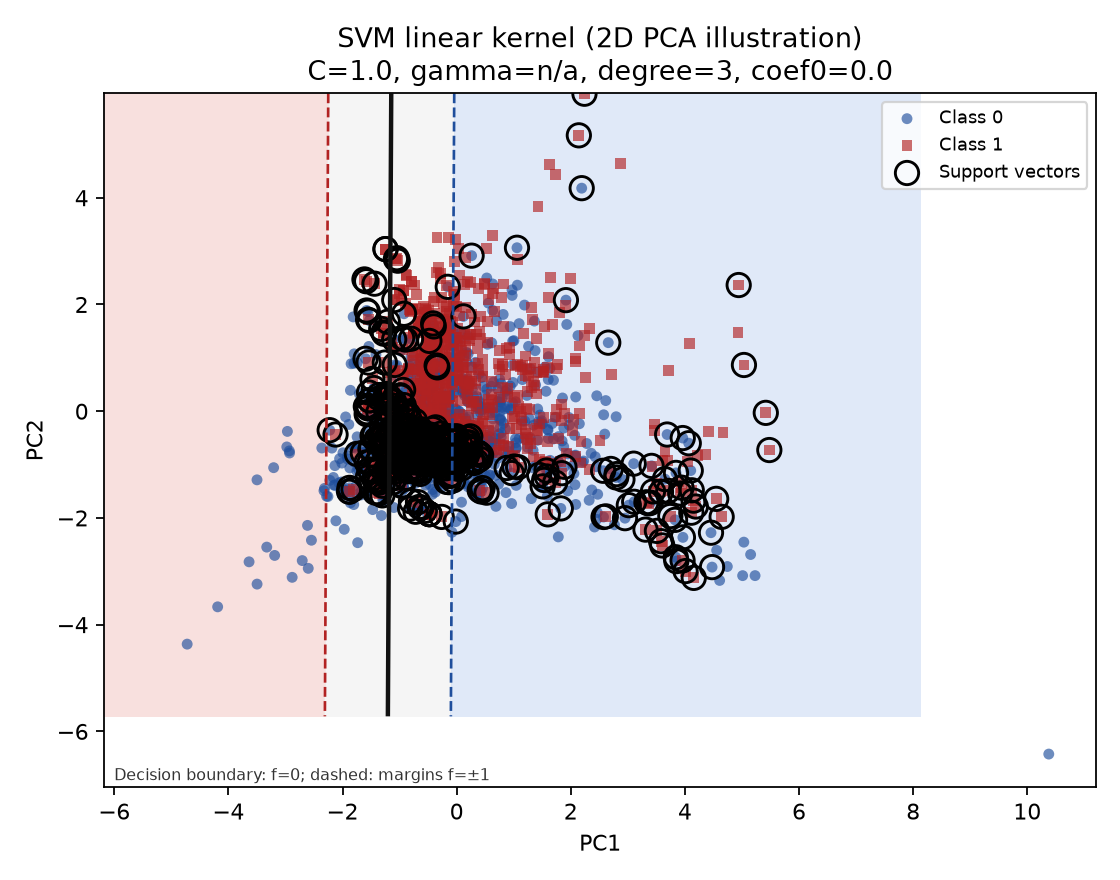

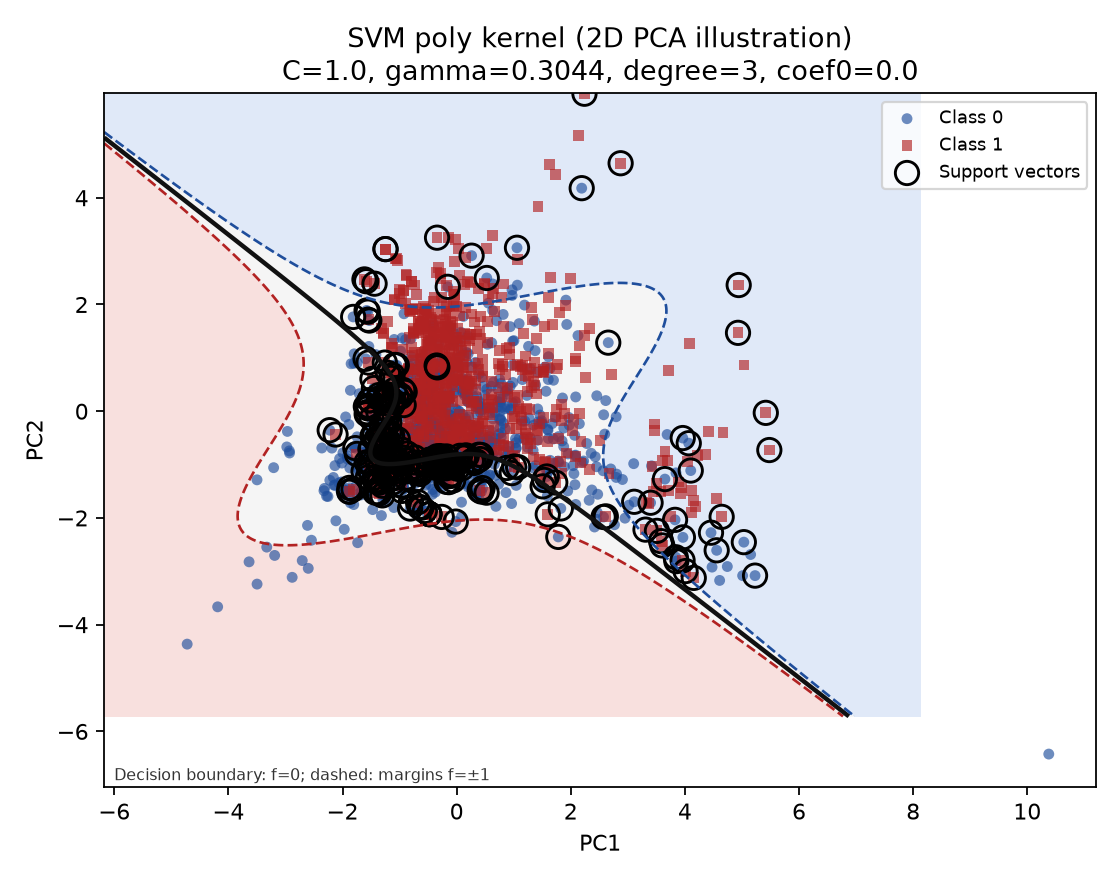

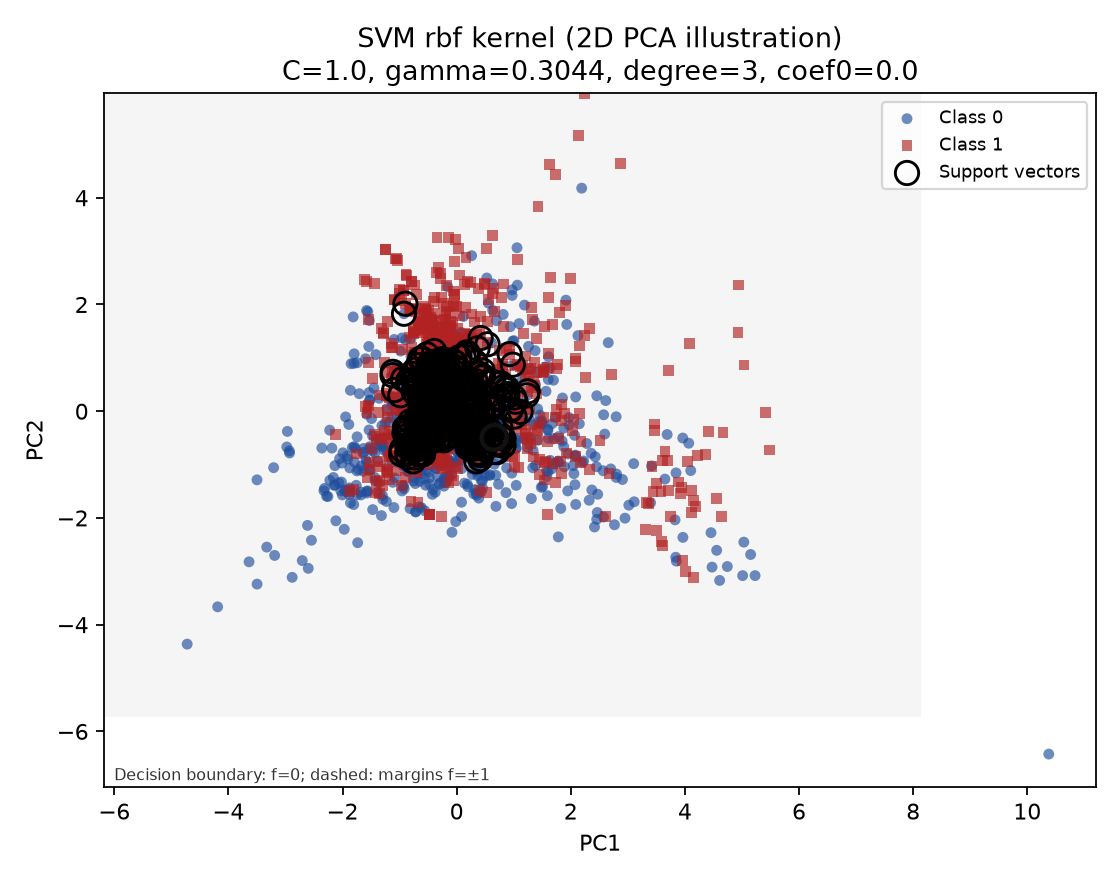

In [4]:
orig_mask = pca_data.orig_tr
X_2d = pca_data.X_tr[orig_mask, :2]
y_2d = pca_data.y_tr[orig_mask]

for kernel_name in ['linear', 'poly', 'rbf']:
    fig_path = Path('docs/laporan/assets/svm') / f'svm-margin-{kernel_name}.png'
    display(Image(filename=str(fig_path), width=480))

## 4. Penyimpanan Model dan Reproduksi Submisi Terbaik Kaggle (`0.86363`)

Model terbaik dilatih pada subset terstratifikasi 15.000 baris dari matriks 89 fitur rekayasa penuh (`C=20.0`, `kernel='rbf'`, `gamma = 1.25 / (d * Var(X_sub))`, `random_state=824`) dengan ambang keputusan `0.0695`.
Sel di bawah memverifikasi serialisasi *round-trip* pada *checkpoint* `output/checkpoints_best/svm_scratch_0.86363.pkl` serta mereproduksi persis berkas submisi `output/submission_svm_best_public.csv`.

In [5]:
X_full, y_full, X_test_full, test_ids, feat_names = load_engineered_final('data', random_state=RANDOM_STATE)
sub_idx = stratified_subset_indices(y_full, np.ones(len(y_full), dtype=bool), max_samples=15000, random_state=RANDOM_STATE)
X_sub, y_sub = X_full[sub_idx], y_full[sub_idx]
expected_gamma = 1.25 / (X_sub.shape[1] * X_sub.var())

ckpt_model_path = Path('output/checkpoints_best/svm_scratch_0.86363.pkl')
svm_best = joblib.load(ckpt_model_path)
print('Loaded model:', svm_best)
print(f'Resolved gamma: {svm_best.gamma_:.10f} (expected: {expected_gamma:.10f})')
assert check_serialization(svm_best, X_test_full[:256]), 'Round-trip serialization check failed!'
print('Verifikasi save/load round-trip identik: OK')

repro_path = save_submission(
    svm_best,
    X_test_full,
    test_ids,
    output_path='output/submission_svm_best_public.csv',
    sample_submission_path='data/sample_submission.csv',
    threshold=0.0695,
)
ref_sub = pd.read_csv('output/checkpoints_best/submission_svm_0.86363.csv')
new_sub = pd.read_csv(repro_path)
pd.testing.assert_frame_equal(ref_sub, new_sub)
print(f'Submisi {repro_path} terverifikasi 100% identik dengan submission_svm_0.86363.csv!')
print(new_sub['is_canceled'].value_counts())
display(new_sub.head())

Loaded model: SVM(C=20.0, kernel='rbf', n_support=5681, converged=True)
Resolved gamma: 0.0216517994 (expected: 0.0216517994)
Verifikasi save/load round-trip identik: OK


Submisi output/submission_svm_best_public.csv terverifikasi 100% identik dengan submission_svm_0.86363.csv!
is_canceled
0    4823
1    2021
Name: count, dtype: int64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,1
4,621586b6,0
